# 酒店预订数据：市场渠道与订单取消行为分析

**香港城市大学 MSc Electronic Commerce · IS6400 课程项目（个人完成） · Notebook 2/4**

基于 Hotel Booking Demand 数据集（119,390 条预订记录、32 个字段），完成变量类型梳理、缺失值检查、频数统计，并通过分组聚合与列联表对比不同市场渠道（market_segment）的预订量与取消率差异。

Question 3

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

bookings = pd.read_csv('../data/hotel_bookings.csv')
bookings.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [2]:
print('Shape:', bookings.shape)
print()
print('dtype:', bookings.dtypes.value_counts())
print()
missing = bookings.isnull().sum()
missing = (missing[missing > 0]).round(4)
pd.DataFrame({'missing': missing,'ratio': (missing / len(bookings)).round(4)})

Shape: (119390, 32)

dtype: int64      16
str        12
float64     4
Name: count, dtype: int64



,missing,ratio
children,4,0.0000
country,488,0.0041
agent,16340,0.1369
company,112593,0.9431


|Variable|Measurement Scale|Data Type|
|---|---|---|
|hotel|nominal|discrete|
|is_canceled|nominal|discrete|
|lead_time|ratio|continuous|
|arrival_date_year|interval|discrete|
|arrival_date_month|ordinal|discrete|
|arrival_date_week_number|interval|discrete|
|arrival_date_day_of_month|interval|discrete|
|stays_in_weekend_nights|ratio|discrete|
|stays_in_week_nights|ratio|discrete|
|adults|children|babies|ratio|discrete|
|meal|nominal|discrete|
|country|nominal|discrete|
|distribution_channel|nominal|discrete|
|previous_cancellations|ratio|discrete|
|reserved_room_type|nominal|discrete|
|booking_changes|ratio|discrete|
|deposit_type|nominal|discrete|
|agent|nominal|discrete|
|company|nominal|discrete|
|day_in_waiting_list|ratio|discrete|
|customer_type|nominal|discrete|
|adr|ratio|continuous|
|required_car_parking_spaces|ratio|discrete|
|total_of_special_requests|ratio|discrete|
|reservation_status|nominal|discrete|
|reservation_status_date|interval|discrete|
|market_segment|nominal|discrete|
|is_repeated_guest|nominal|discrete|
|previous_bookings_not_canceled|ratio|discrete|
|assigned_room_type|nominal|discrete|

In [3]:
dataset = ['market_segment', 'is_canceled']

for col in dataset:
    frequency = bookings[col].value_counts()
    percentage = bookings[col].value_counts(normalize=True).round(4)*100
    table = pd.DataFrame({
        'Frequency': frequency,
        'Percentage': percentage
    })
    print(col)
    display(table)

market_segment


,Frequency,Percentage
market_segment,,
Online TA,56477,47.30
Offline TA/TO,24219,20.29
Groups,19811,16.59
Direct,12606,10.56
Corporate,5295,4.44
Complementary,743,0.62
Aviation,237,0.20
Undefined,2,0.00


is_canceled


,Frequency,Percentage
is_canceled,,
0,75166,62.96
1,44224,37.04


In [4]:
#Summary statistics: cancellation rate by market segment
seg_stats = bookings.groupby('market_segment')['is_canceled'].agg(['count', 'mean'])
seg_stats['cancel_rate_%'] = (seg_stats['mean'] * 100).round(2)
seg_stats = seg_stats.rename(columns={'count': 'bookings', 'mean': 'cancel_rate'})
print(seg_stats.sort_values('cancel_rate', ascending=False).round(4))

#Contingency table
ct = pd.crosstab(bookings['market_segment'], bookings['is_canceled'])
ct.columns = ['Not canceled', 'Canceled']
ct['Total'] = ct.sum(axis=1)
ct['Cancel rate %'] = (ct['Canceled'] / ct['Total'] * 100).round(1)
display(ct)

                bookings  cancel_rate  cancel_rate_%
market_segment                                      
Undefined              2       1.0000         100.00
Groups             19811       0.6106          61.06
Online TA          56477       0.3672          36.72
Offline TA/TO      24219       0.3432          34.32
Aviation             237       0.2194          21.94
Corporate           5295       0.1873          18.73
Direct             12606       0.1534          15.34
Complementary        743       0.1306          13.06


,Not canceled,Canceled,Total,Cancel rate %
market_segment,,,,
Aviation,185,52,237,21.9
Complementary,646,97,743,13.1
Corporate,4303,992,5295,18.7
Direct,10672,1934,12606,15.3
Groups,7714,12097,19811,61.1
Offline TA/TO,15908,8311,24219,34.3
Online TA,35738,20739,56477,36.7
Undefined,0,2,2,100.0


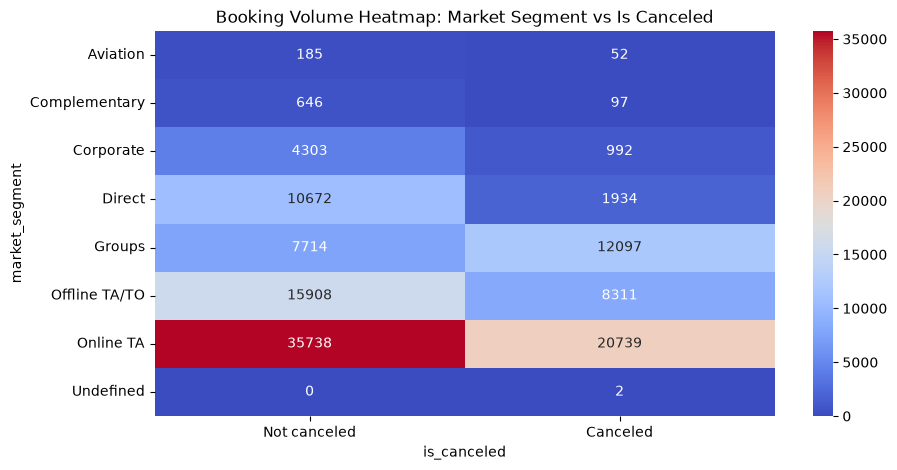

In [5]:
ct = pd.crosstab(bookings['market_segment'], bookings['is_canceled'])
ct.columns = ['Not canceled', 'Canceled']
plt.figure(figsize=(10, 5))
sns.heatmap(ct, annot=True, fmt='d', cmap='coolwarm')
plt.title('Booking Volume Heatmap: Market Segment vs Is Canceled')
plt.xlabel('is_canceled')
plt.ylabel('market_segment')
plt.show()

There is a noticeable relationship between market_segment and is_canceled. Online TA has the most bookings, with 56,477 bookings, accounting for about 47% of all bookings. Offline TA/TO, Groups, and Direct have fewer bookings.

The cancellation rates are also different across the market segments. Groups has the highest cancellation rate, at around 61%, while Direct, Corporate, and Complementary have much lower rates, at about 15%, 19%, and 13%, respectively. Online TA has a cancellation rate of around 37%, which is close to the overall cancellation rate. Because Online TA has a much larger number of bookings, it also has a large number of cancellations.

The plots show a similar pattern. Groups has a much higher cancellation rate than Direct, while some smaller segments also show different cancellation patterns. This means that the number of bookings and the cancellation rate should be considered separately. Overall, market_segment seems to have a clear relationship with cancellation behaviour and could be useful for further analysis and prediction.